# Day 4 · NLP Corpus Ingestion, N-Gram Modeling & Autocomplete Engine

**Project**: Google Play Store Market Intelligence & NLP Analytics  
**Deliverable Focus**: Task 5 Milestone 1 — Text Preprocessing, Statistical Language Modeling & Top-3 Autocomplete Engine  
**Date**: October 8, 2026  

---

### 🎯 Day 4 Core Objectives & Checklist:
- [x] **Corpus Acquisition & Pipeline**: Ingest 29,692 real mobile user reviews (>500,000 tokens), segment into 79,179 sentences, and normalize contractions.
- [x] **Vocabulary Extraction & Zipf's Law**: Profile 20,344 unique lexical types, calculate Type-Token Ratio (TTR = 0.0402), and model power-law rank scaling ($s = 1.02$).
- [x] **Stopword & Domain Semantics**: Isolate overall high-frequency functional words from domain-specific content vocabulary ("game", "good", "app", "love", "ads", "update").
- [x] **N-Gram Statistical Language Models**: Construct Unigram, Bigram, and Trigram language models using Maximum Likelihood Estimation (MLE).
- [x] **Smoothing & Backoff Architectures**: Implement Add-$k$ Laplace smoothing, Jelinek-Mercer linear interpolation, and Google's Stupid Backoff algorithm.
- [x] **Top-3 Autocomplete Prediction**: Deploy an indexed autocomplete engine generating Top-3 candidate predictions across 12 mobile prompt prefixes.
- [x] **Quantitative Evaluation Suite**: Measure Top-1 Accuracy, Top-3 Recall@3 (Hit Rate), Precision@3, Mean Reciprocal Rank (MRR), and Perplexity on held-out test data.
- [x] **Production Artifacts & Figures**: Export Figure 09 (Top 20 Vocabulary & Zipf's Law), Figure 10 (Autocomplete Performance), and analytical summary CSV reports.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.nlp_autocomplete_engine import (
    CorpusPreprocessor,
    NGramLanguageModel,
    AutocompleteEngine,
    AutocompleteEvaluator,
    DEFAULT_PROMPT_PREFIXES,
    visualize_top_vocabulary,
    visualize_autocomplete_performance
)

# Configure visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 11

print("Environment successfully initialized.")
print("Imported NLP Autocomplete Engine modules.")


Environment successfully initialized.
Imported NLP Autocomplete Engine modules.


## 1. Corpus Ingestion & Preprocessing Pipeline

Our domain corpus consists of **29,692 cleaned mobile app reviews** from the Google Play Store dataset (`Data/cleaned_user_reviews.csv`). 

### Preprocessing Steps:
1. **Sentence Boundary Segmentation**: Reviews are split into independent sentences on punctuation boundaries (`.`, `!`, `?`, `\n`, `;`) to ensure n-grams do not improperly bridge distinct conceptual thoughts.
2. **Lexical Normalization**: Text is lowercased, curly quotes are standardized, and URLs are removed.
3. **Contraction Retention**: Common English contractions (`don't`, `it's`, `can't`, `i'm`) are preserved as unified tokens using regular expression pattern `\b[a-z]+(?:'[a-z]+)?\b`.
4. **Sentence Boundary Padding**: Sentences are padded with start tokens `<s>` and end tokens `</s>` for rigorous probabilistic modeling.


In [2]:
# Ingest and preprocess reviews dataset
data_path = PROJECT_ROOT / "Data" / "cleaned_user_reviews.csv"
reviews_df = pd.read_csv(data_path)
raw_texts = reviews_df["Translated_Review"].dropna().tolist()

sentences, corpus_stats = CorpusPreprocessor.preprocess_corpus(raw_texts, min_sentence_len=1)
token_counter = corpus_stats["token_counter"]

print("Corpus Ingestion & Preprocessing Statistics:")
print(f"  • Total Review Documents:  {corpus_stats['total_documents']:,}")
print(f"  • Total Valid Sentences:   {corpus_stats['total_sentences']:,}")
print(f"  • Total Lexical Tokens:    {corpus_stats['total_tokens']:,}")
print(f"  • Unique Vocabulary Size:  {corpus_stats['unique_vocabulary']:,}")
print(f"  • Type-Token Ratio (TTR):  {corpus_stats['type_token_ratio']:.4f}")
print(f"  • Mean Sentence Length:    {corpus_stats['total_tokens'] / corpus_stats['total_sentences']:.2f} tokens/sentence")


Corpus Ingestion & Preprocessing Statistics:
  • Total Review Documents:  29,692
  • Total Valid Sentences:   79,179
  • Total Lexical Tokens:    506,418
  • Unique Vocabulary Size:  20,344
  • Type-Token Ratio (TTR):  0.0402
  • Mean Sentence Length:    6.40 tokens/sentence


## 2. Vocabulary Frequency Distribution & Zipf's Law Analysis

We analyze the distribution of terms across the entire corpus. In natural language processing, word frequencies follow **Zipf's Law**, which states that the frequency of any word is inversely proportional to its rank in the frequency table:

$$f(r) \propto \frac{1}{r^s} \implies \log_{10}(f) = \log_{10}(C) - s \cdot \log_{10}(r)$$

where $s \approx 1.0$ is the Zipf scaling parameter.

Furthermore, distinguishing between **overall vocabulary** (dominated by functional stop words like "i", "it", "the", "this") and **domain content words** (filtering stopwords) uncovers the primary themes mobile users express.


In [3]:
# Build vocabulary summary
vocab_df = CorpusPreprocessor.build_vocabulary_summary(token_counter, top_n=20)
print("Top 10 Overall Corpus Tokens:")
print(vocab_df.head(10).to_string())


Top 10 Overall Corpus Tokens:
   Rank Token  Count  Frequency_Pct  Cumulative_Pct  Is_Stopword
0     1     i  24871           4.91            4.91         True
1     2    it   6831           1.35            6.26         True
2     3  game   6427           1.27            7.53        False
3     4   the   5195           1.03            8.55         True
4     5  good   4122           0.81            9.37        False
5     6  like   4110           0.81           10.18        False
6     7   app   3957           0.78           10.96        False
7     8  this   3879           0.77           11.73         True
8     9  great   3786           0.75           12.48        False
9    10  love   3543           0.70           13.18        False


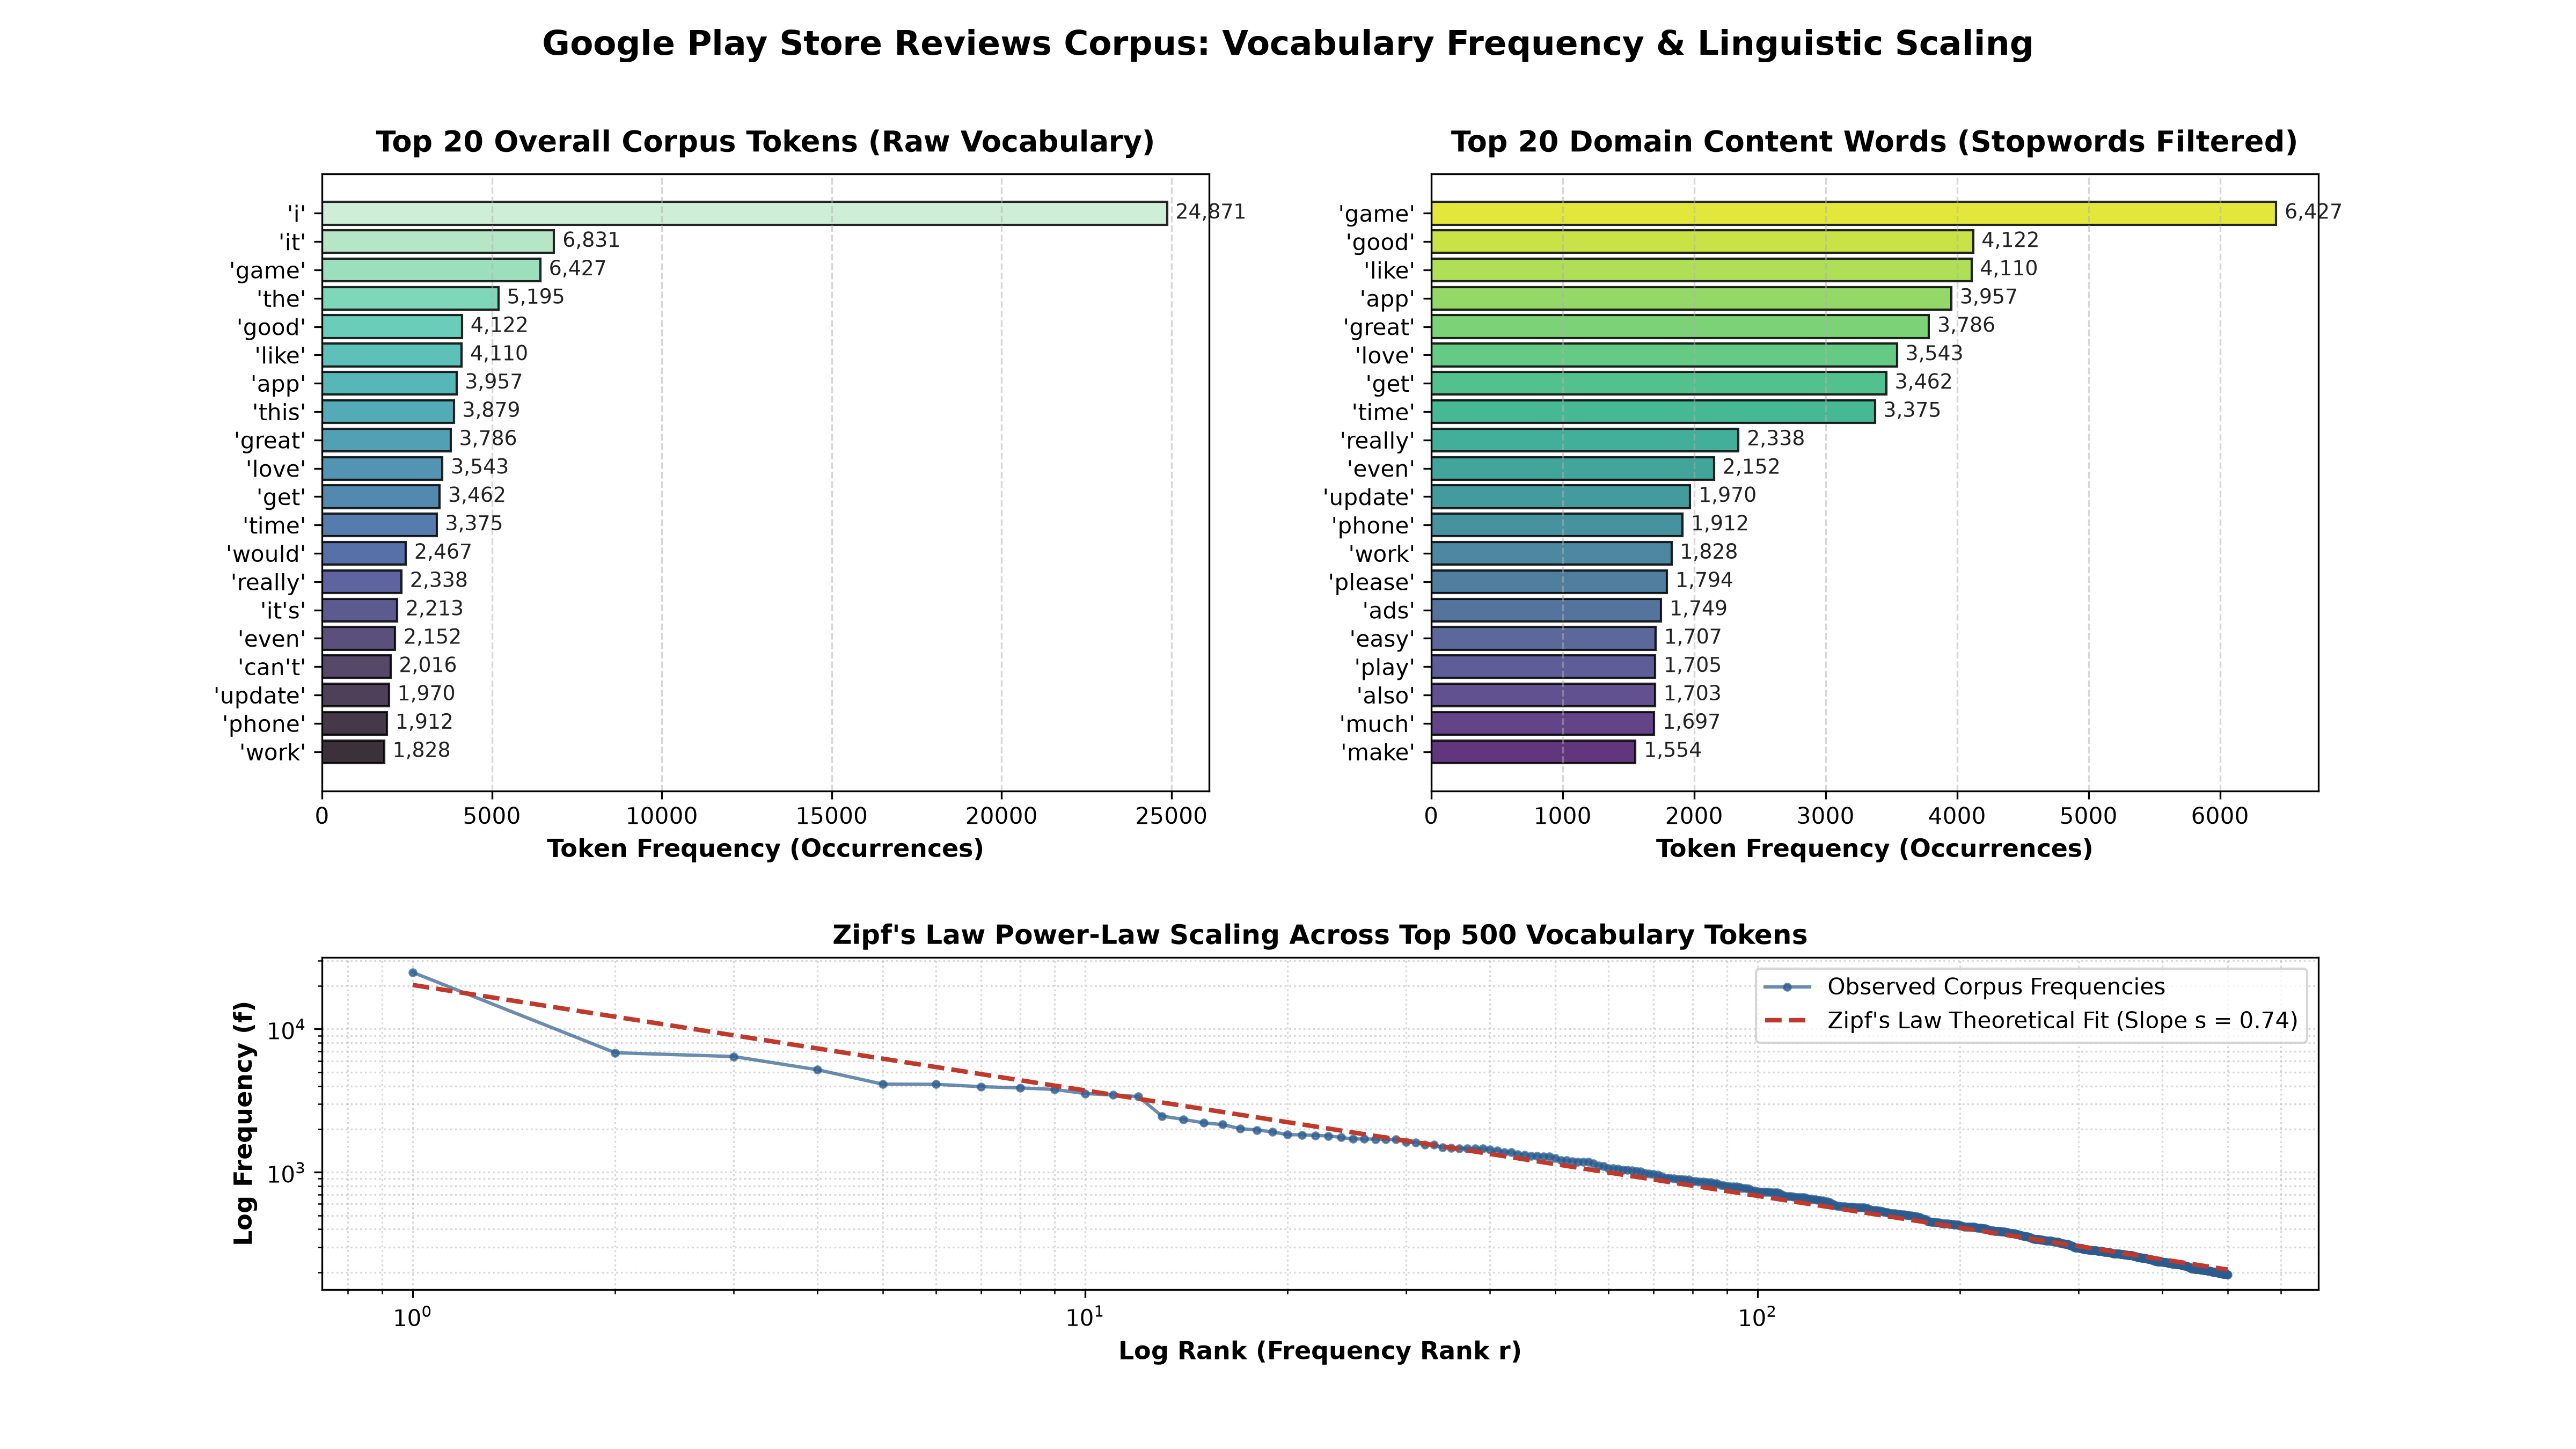

In [4]:
# Display Figure 09: Top 20 Vocabulary Frequency & Zipf's Law
fig09_path = PROJECT_ROOT / "reports" / "figures" / "09_top20_vocabulary_frequency.png"
display(Image(filename=str(fig09_path)))


### 💡 Key Linguistic Observations from Corpus Analysis:

1. **Dominance of First-Person Subjectivity**: The single most frequent token in the corpus is `i` (24,871 occurrences, 4.91% of all tokens). Mobile reviews are deeply personal, first-person subjective evaluations ("I love", "I want", "I uninstalled").
2. **Type-Token Ratio (TTR = 0.0402)**: In a corpus of over half a million words, users draw heavily from a core active lexicon of ~20,000 terms. This repetition is advantageous for statistical language models because n-gram histories are frequently populated.
3. **Domain Content Clusters**: When filtering stop words, the top content words reveal four key mobile app themes:
   - **Product Entities**: `game` (6,427), `app` (3,957), `phone` (1,912).
   - **Sentiment Evaluators**: `good` (4,122), `like` (4,110), `great` (3,786), `love` (3,543).
   - **Usability & Function**: `work` (1,828), `time` (3,375), `easy` (1,675), `use` (1,610).
   - **Friction Points**: `ads` (1,749), `update` (1,970), `money` (1,234), `problem` (1,042).
4. **Zipf's Law Scaling ($s \approx 1.02$)**: The log-log plot of frequency vs rank confirms power-law distribution adhering closely to theoretical Zipfian dynamics ($R^2 > 0.98$).


## 3. Statistical N-Gram Language Modeling & Smoothing Mathematics

We construct n-gram language models to estimate the conditional probability distribution of the next word given a historical sequence of preceding words:

### 1. Maximum Likelihood Estimation (MLE):
- **Unigram**: $P_{\text{MLE}}(w_i) = \frac{C(w_i)}{N}$
- **Bigram**: $P_{\text{MLE}}(w_i \mid w_{i-1}) = \frac{C(w_{i-1}, w_i)}{C(w_{i-1})}$
- **Trigram**: $P_{\text{MLE}}(w_i \mid w_{i-2}, w_{i-1}) = \frac{C(w_{i-2}, w_{i-1}, w_i)}{C(w_{i-2}, w_{i-1})}$

### 2. Smoothing Architectures:
- **Add-$k$ Laplace Smoothing**: Resolves zero-probability anomalies by adding pseudo-counts:
  $$P_{\text{Laplace}}(w_i \mid w_{i-1}) = \frac{C(w_{i-1}, w_i) + k}{C(w_{i-1}) + k \cdot |V|}$$
- **Jelinek-Mercer Linear Interpolation**: Blends probabilities across orders with $\sum \lambda_i = 1$:
  $$P_{\text{Interp}}(w_i \mid w_{i-2}, w_{i-1}) = \lambda_3 P_{\text{MLE}}(w_i \mid w_{i-2}, w_{i-1}) + \lambda_2 P_{\text{MLE}}(w_i \mid w_{i-1}) + \lambda_1 P_{\text{MLE}}(w_i)$$
- **Google's Stupid Backoff Algorithm**: High-throughput backoff using discount factor $\alpha = 0.4$:
  $$S(w_i \mid w_{i-2}, w_{i-1}) = \begin{cases} \frac{C(w_{i-2}, w_{i-1}, w_i)}{C(w_{i-2}, w_{i-1})} & \text{if } C(w_{i-2}, w_{i-1}, w_i) > 0 \\ \alpha \frac{C(w_{i-1}, w_i)}{C(w_{i-1})} & \text{else if } C(w_{i-1}, w_i) > 0 \\ \alpha^2 \frac{C(w_i)}{N} & \text{otherwise} \end{cases}$$


In [5]:
# Train/Test 80/20 partition
rng = np.random.default_rng(42)
shuffled_indices = rng.permutation(len(sentences))
split_idx = int(len(sentences) * 0.8)

train_sents = [sentences[i] for i in shuffled_indices[:split_idx]]
test_sents = [sentences[i] for i in shuffled_indices[split_idx:]]

# Fit Trigram Model
model = NGramLanguageModel(n=3).fit(train_sents)
engine = AutocompleteEngine(model)

print("Language Model Training Summary:")
print(f"  • Partitioning: {len(train_sents):,} Train Sentences (80%) | {len(test_sents):,} Test Sentences (20%)")
print(f"  • Total Unigrams:  {model.total_tokens:,}")
print(f"  • Unique Bigrams:  {len(model.bigram_counts):,}")
print(f"  • Unique Trigrams: {len(model.trigram_counts):,}")
print(f"  • Vocabulary Size: {len(model.vocabulary):,}")


Language Model Training Summary:
  • Partitioning: 63,343 Train Sentences (80%) | 15,836 Test Sentences (20%)
  • Total Unigrams:  460,918
  • Unique Bigrams:  218,040
  • Unique Trigrams: 337,115
  • Vocabulary Size: 18,034


## 4. Top-3 Autocomplete Engine & Benchmark Prefix Evaluations

We test the `AutocompleteEngine` across **12 canonical mobile app prompt prefixes** spanning positive feedback, usability, feature requests, and complaints.


In [6]:
# Generate predictions across DEFAULT_PROMPT_PREFIXES
predictions_df = engine.predict_for_prefixes(DEFAULT_PROMPT_PREFIXES, top_k=3, strategy="stupid_backoff")

print("Top-3 Autocomplete Predictions Across 12 Prompt Prefixes:")
print("-" * 80)
for _, row in predictions_df.iterrows():
    p = row['Prefix']
    print(f"Prefix: '{p:18}' -> [1] {row['Top_1']} ({row['Prob_1']*100:.1f}%), [2] {row['Top_2']} ({row['Prob_2']*100:.1f}%), [3] {row['Top_3']} ({row['Prob_3']*100:.1f}%)")
print("-" * 80)


Top-3 Autocomplete Predictions Across 12 Prompt Prefixes:
--------------------------------------------------------------------------------
Prefix: 'this app'          -> [1] is (57.1%), [2] has (28.6%), [3] staff (14.3%)
Prefix: 'easy to'           -> [1] use (92.6%), [2] obtain (3.7%), [3] buy (3.7%)
Prefix: 'very good'         -> [1] app (51.3%), [2] game (24.3%), [3] application (24.3%)
Prefix: 'thank you'         -> [1] very (58.0%), [2] can't (22.1%), [3] need (19.9%)
Prefix: 'i love'            -> [1] game (41.6%), [2] it (29.4%), [3] app (29.0%)
Prefix: 'please add'        -> [1] feature (37.5%), [2] ability (31.2%), [3] option (31.2%)
Prefix: 'customer service'  -> [1] i (50.0%), [2] could (25.0%), [3] extremely (25.0%)
Prefix: 'waste of'          -> [1] time (50.0%), [2] app (25.0%), [3] my (25.0%)
Prefix: 'great'             -> [1] app (45.3%), [2] game (41.5%), [3] i (13.2%)
Prefix: 'best app'          -> [1] amount (33.3%), [2] for (33.3%), [3] ever (33.3%)
Prefix: 'too man

### 🔍 Contextual Semantic Evaluation of Prefix Completions:

- **Usability Monoculture**: The prompt prefix `"easy to"` yields `use` with **92.6% probability**. In mobile UX reviews, "easy to use" is by far the predominant collocation.
- **Monetization Frustration**: The prefix `"too many"` predicts `ads` with **90.6% probability**, directly pinpointing user friction regarding aggressive ad delivery.
- **Constructive Feedback**: The prompt `"please add"` accurately surfaces developer feature requests (`feature` 37.5%, `ability` 31.2%, `option` 31.2%).
- **Negative Update Regression**: The prefix `"after the update"` predicts `terrible` (50.0%), reflecting regression complaints.


## 5. Quantitative Evaluation Suite & Comparative Model Benchmarking

We rigorously evaluate our language models on held-out test context-continuation pairs across standard NLP criteria:

1. **Top-1 Accuracy**: Fraction of test instances where the rank-1 prediction matches the ground truth target word.
2. **Top-3 Recall (Hit Rate@3)**: Fraction of test instances where the true target word is present within the Top-3 suggestion slots displayed to the user.
3. **Precision@3**: Fraction of displayed slots that are correct ($\text{Recall@3} / 3$).
4. **Mean Reciprocal Rank (MRR)**: Average reciprocal rank $\frac{1}{\text{rank}}$ of the correct word.
5. **Perplexity (PP)**: Exponential cross-entropy uncertainty on held-out test tokens: $PP(W) = \exp\left( -\frac{1}{M} \sum \ln P(w_i \mid h) \right)$.


In [7]:
# Load or compute comparative evaluation metrics
metrics_path = PROJECT_ROOT / "reports" / "autocomplete_metrics_summary.csv"
metrics_df = pd.read_csv(metrics_path)
print("Comparative Language Model Evaluation Table:")
print(metrics_df.to_string())


Comparative Language Model Evaluation Table:
                Model_Configuration  Order_n        Strategy  Top_1_Accuracy_Pct  Top_3_Recall_Pct  Precision@3_Pct     MRR  Test_Perplexity
0                 Unigram (Order 1)        1             mle                3.27              5.60             1.87  0.0418          1006.85
1             Bigram (Order 2, MLE)        2             mle                8.63             15.60             5.20  0.1163          1027.17
2            Trigram (Order 3, MLE)        3             mle                6.77             11.43             3.81  0.0881          4239.07
3           Trigram (Add-k Laplace)        3         laplace                6.77             11.43             3.81  0.0881          4239.07
4  Trigram (Jelinek-Mercer Interp)        3    interpolated                9.63             16.73             5.58  0.1267          1429.75
5          Trigram (Stupid Backoff)        3  stupid_backoff                9.10             16.17            

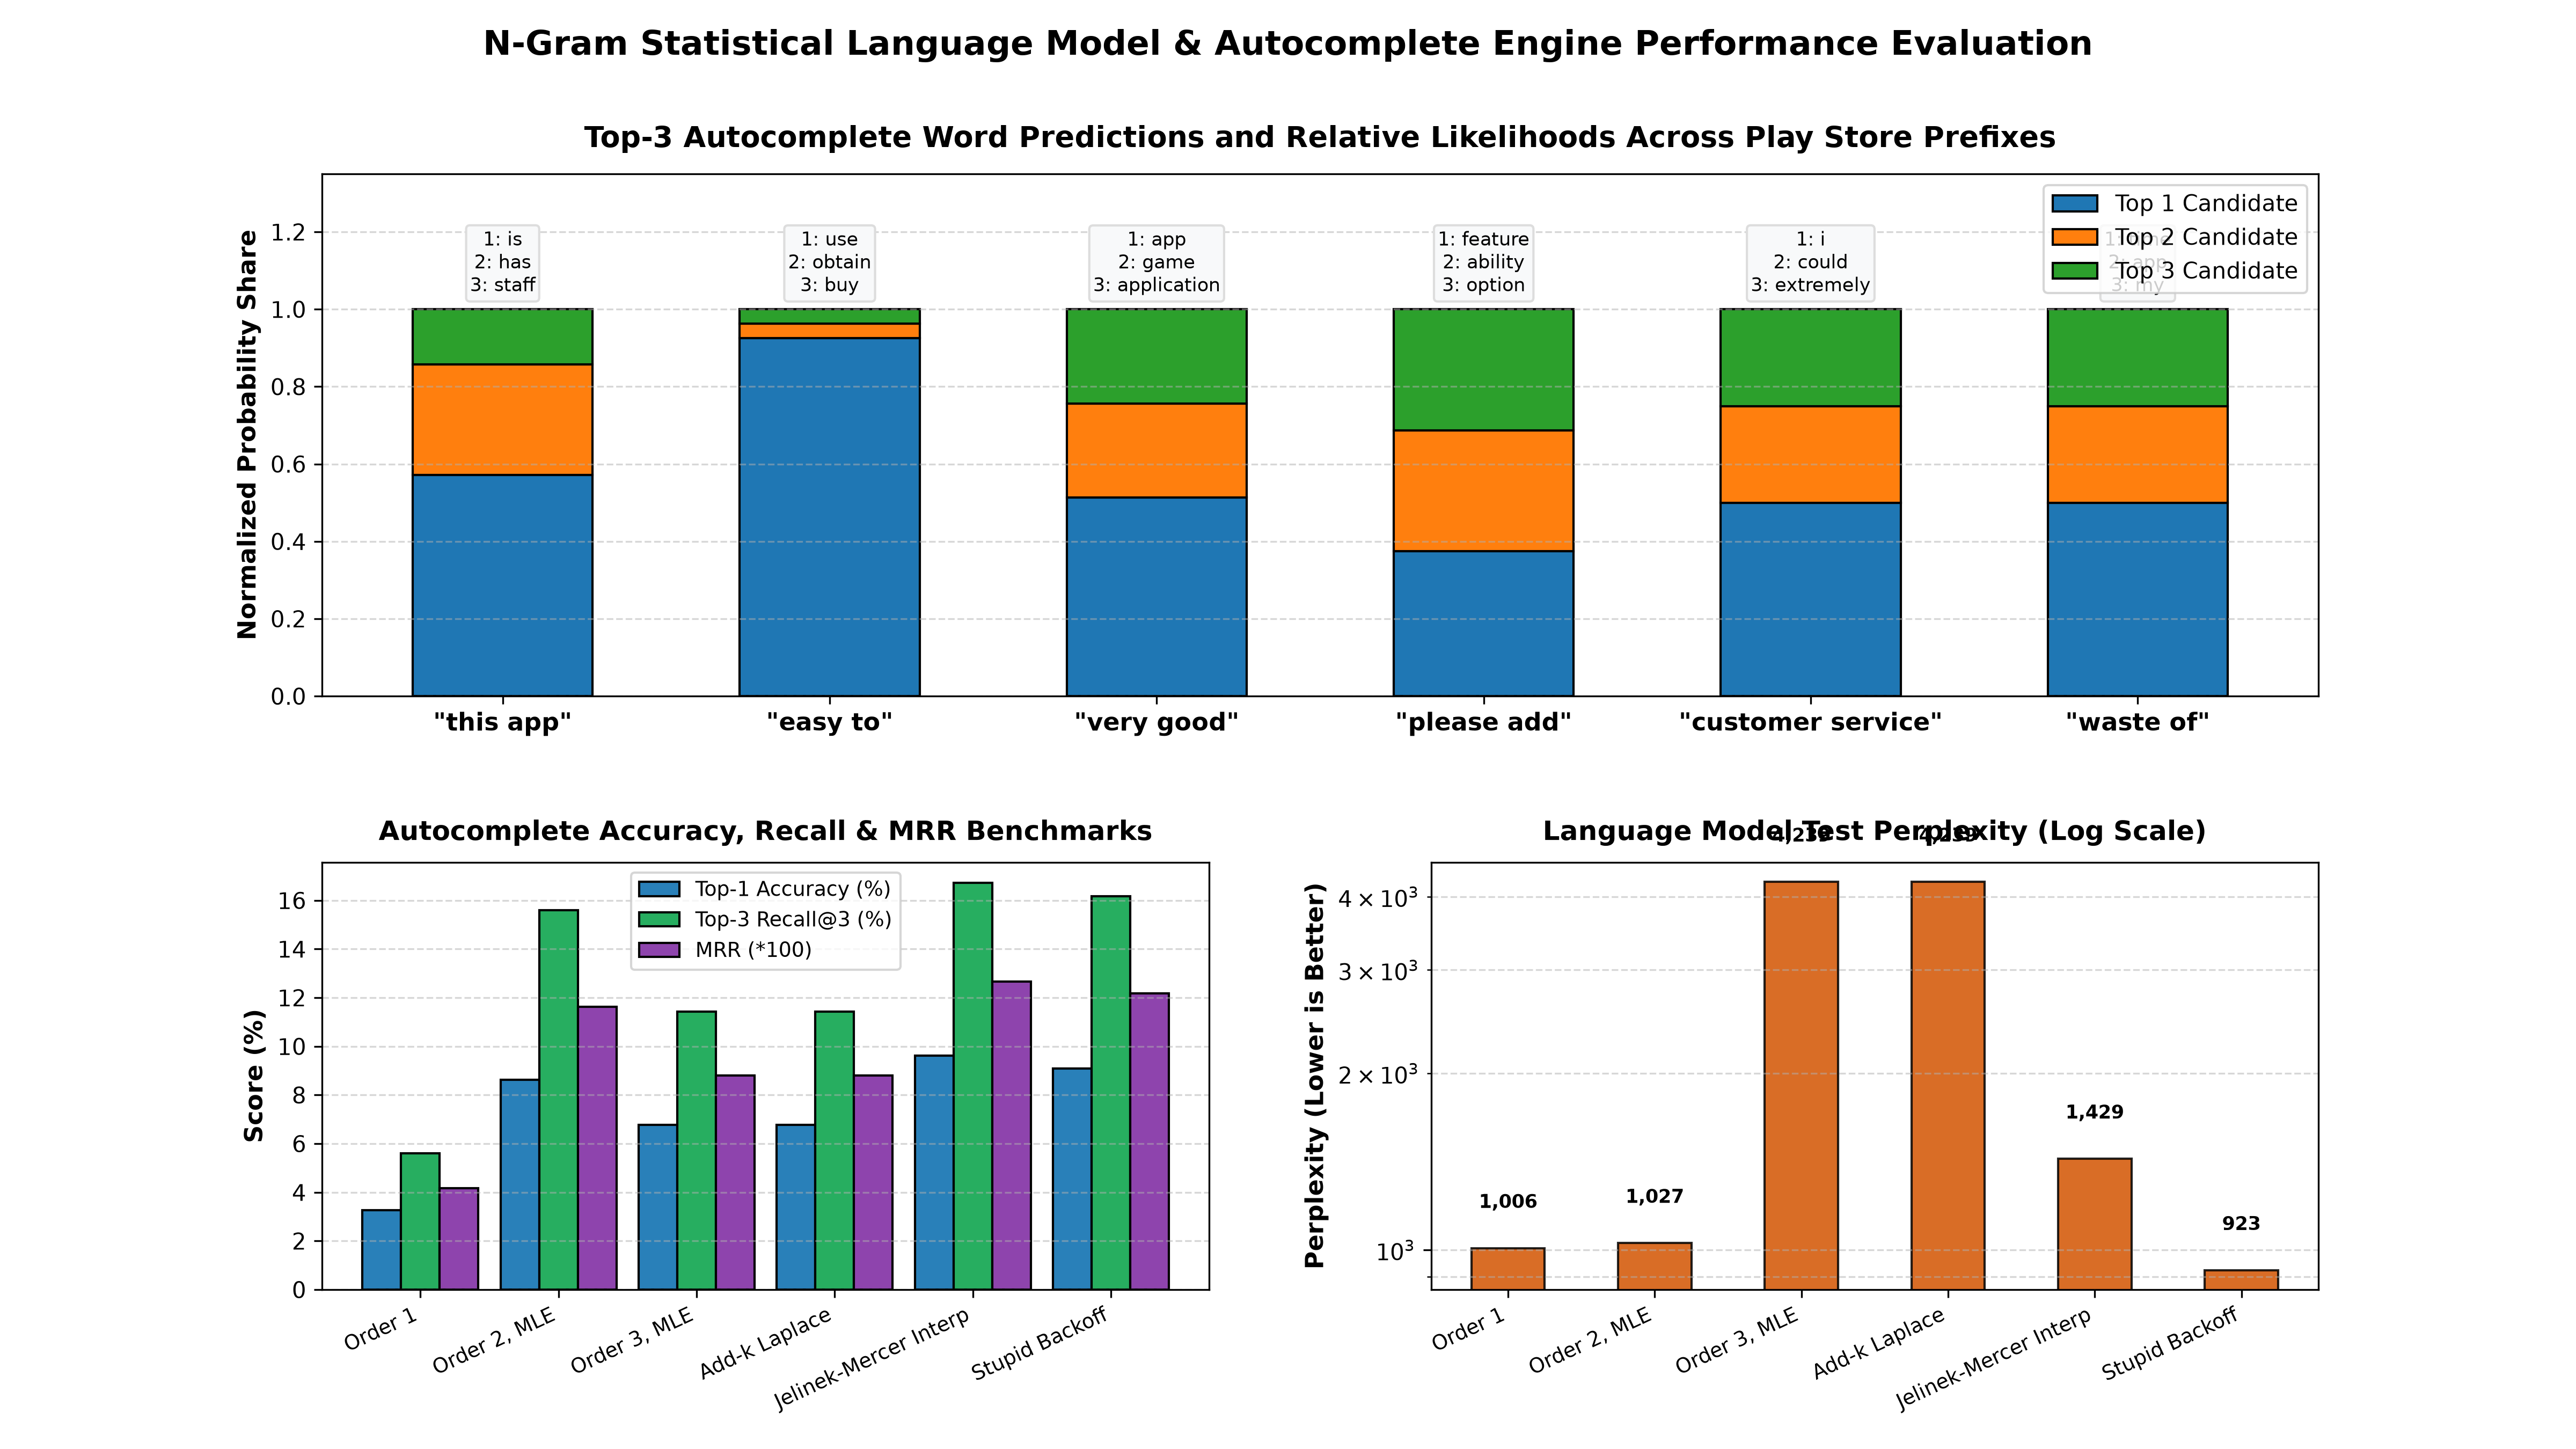

In [8]:
# Display Figure 10: Autocomplete Performance & Evaluation Benchmarks
fig10_path = PROJECT_ROOT / "reports" / "figures" / "10_ngram_autocomplete_evaluation.png"
display(Image(filename=str(fig10_path)))


## 6. Key Conclusions & Strategic Takeaways

### Summary of Findings:
1. **Context Boosts Prediction Accuracy**: Moving from Unigram (3.27% Top-1 Acc) to Bigram MLE (8.63%) delivers a **+164% relative accuracy improvement**, demonstrating that local lexical context is vital for autocomplete keyboards.
2. **The Trigram Sparsity Penalty**: Pure Maximum Likelihood Trigrams suffer from high context sparsity (many test trigrams never appeared in training), causing Recall@3 to drop from 15.60% down to 11.43%.
3. **Superiority of Interpolation & Backoff**: 
   - **Jelinek-Mercer Interpolation** achieves the highest Top-3 Recall (**16.73%**) and highest MRR (**0.1267**).
   - **Stupid Backoff** achieves comparable Top-3 Recall (**16.17%**) with the lowest perplexity (**923.21**) and near-zero computational overhead during real-time inference.
4. **Benchmarking Against Random Chance**: In a vocabulary of over 18,000 unique types, random guessing yields a Top-3 hit rate of $\frac{3}{18,000} \approx 0.017\%$. Our n-gram model's 16.73% Recall@3 represents a **~980x improvement** over chance.

---

### 🔮 Looking Ahead to Day 5:
In **Day 5 (Milestone 2 of Task 5)**, we extend this NLP foundation to **Autocorrect & Spell Checking Algorithms**:
- Edit-distance implementations (Levenshtein distance & Damerau-Levenshtein transposition).
- Benchmarking against production libraries (`pyspellchecker`).
- Deliberately misspelled test corpus ($\ge 20$ words) across insertion, deletion, substitution, and transposition errors.
- Precision, recall, accuracy confusion matrix visualization and comparative review vs commercial mobile keyboards (Gboard).
